In [1]:
# 1. IMPORTACIÓN DE BIBLIOTECAS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import sys


In [2]:
# 2. LOCALIZAR LA RAÍZ DEL PROYECTO
# Obtener el directorio actual de ejecución
CURRENT_DIR = Path.cwd().resolve()

# Buscar config.py en el directorio actual y sus carpetas superiores
ROOT_DIR = None

for directory in [CURRENT_DIR, *CURRENT_DIR.parents]:
    if (directory / "config.py").is_file():
        ROOT_DIR = directory
        break

# Comprobar que encontramos la raíz
if ROOT_DIR is None:
    raise FileNotFoundError(
        "No se encontró config.py. "
        "Comprueba que el notebook está dentro del proyecto."
    )

# Agregar la raíz a las rutas de búsqueda de Python
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

# Importar las rutas de nuestro proyecto
from config import RAW_DATA_DIR


In [3]:
# 3. CARGAR EL DATASET
# Definir la ubicación del archivo CSV
FILE_PATH = RAW_DATA_DIR / "breast_cancer_wisconsin.csv"

# Comprobar que el archivo existe
if not FILE_PATH.is_file():
    raise FileNotFoundError(
        f"No se encontró el dataset en: {FILE_PATH}"
    )

# Leer el archivo utilizando Pandas
df = pd.read_csv(FILE_PATH)

print("\nDataset cargado correctamente")
print("Dimensiones:", df.shape)


Dataset cargado correctamente
Dimensiones: (569, 32)


In [4]:
# 4. VISUALIZAR LOS PRIMEROS REGISTROS
display(df.head())

,ID,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,842302,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,842517,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,84300903,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,84348301,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,84358402,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


In [5]:
# 5. INFORMACIÓN GENERAL DEL DATASET
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  569 non-null    int64  
 1   radius1             569 non-null    float64
 2   texture1            569 non-null    float64
 3   perimeter1          569 non-null    float64
 4   area1               569 non-null    float64
 5   smoothness1         569 non-null    float64
 6   compactness1        569 non-null    float64
 7   concavity1          569 non-null    float64
 8   concave_points1     569 non-null    float64
 9   symmetry1           569 non-null    float64
 10  fractal_dimension1  569 non-null    float64
 11  radius2             569 non-null    float64
 12  texture2            569 non-null    float64
 13  perimeter2          569 non-null    float64
 14  area2               569 non-null    float64
 15  smoothness2         569 non-null    float64
 16  compactness2       

In [6]:
# 6. IDENTIFICAR VALORES FALTANTES
missing_values = df.isnull().sum()

print("\nValores faltantes por columna:")
display(missing_values)



Valores faltantes por columna:


ID                    0
radius1               0
texture1              0
perimeter1            0
area1                 0
smoothness1           0
compactness1          0
concavity1            0
concave_points1       0
symmetry1             0
fractal_dimension1    0
radius2               0
texture2              0
perimeter2            0
area2                 0
smoothness2           0
compactness2          0
concavity2            0
concave_points2       0
symmetry2             0
fractal_dimension2    0
radius3               0
texture3              0
perimeter3            0
area3                 0
smoothness3           0
compactness3          0
concavity3            0
concave_points3       0
symmetry3             0
fractal_dimension3    0
Diagnosis             0
dtype: int64

In [7]:
# 7. IDENTIFICAR REGISTROS DUPLICADOS

duplicate_count = df.duplicated().sum()

print("\nCantidad de registros duplicados:", duplicate_count)


Cantidad de registros duplicados: 0


In [8]:
# 8. DISTRIBUCIÓN DE LOS DIAGNÓSTICOS
# ============================================================

diagnosis_counts = df["Diagnosis"].value_counts()

print("\nDistribución de diagnósticos:")
display(diagnosis_counts)

print("\nPorcentaje de cada diagnóstico:")
display((df["Diagnosis"].value_counts(normalize=True) * 100).round(2))


Distribución de diagnósticos:


Diagnosis
B    357
M    212
Name: count, dtype: int64


Porcentaje de cada diagnóstico:


Diagnosis
B    62.74
M    37.26
Name: proportion, dtype: float64

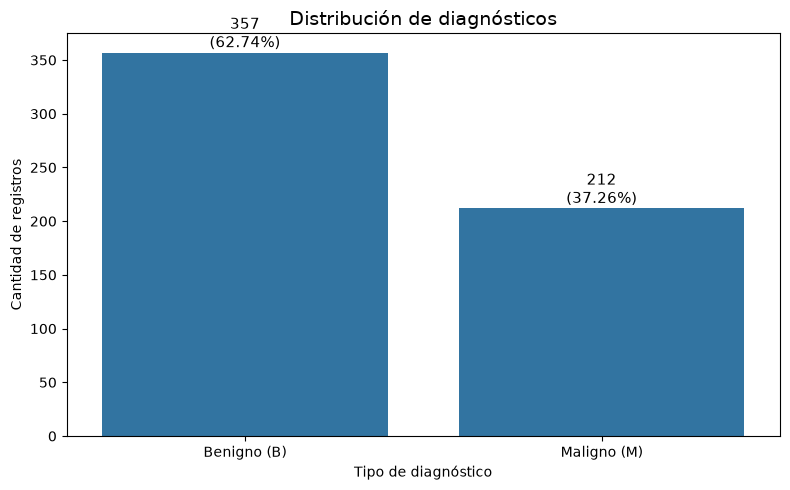

In [9]:
# GRÁFICA 1: DISTRIBUCIÓN DE DIAGNÓSTICOS
# Obtener la cantidad de registros por diagnóstico
from config import FIGURES_DIR
diagnosis_counts = df["Diagnosis"].value_counts().reindex(["B", "M"])

# Calcular el porcentaje de cada clase
diagnosis_percentages = (
    df["Diagnosis"].value_counts(normalize=True)
    .reindex(["B", "M"]) * 100
)

# Crear la figura
fig, ax = plt.subplots(figsize=(8, 5))

# Crear gráfica de barras
sns.barplot(
    x=diagnosis_counts.index,
    y=diagnosis_counts.values,
    ax=ax
)

# Agregar cantidad y porcentaje encima de cada barra
for i, diagnosis in enumerate(diagnosis_counts.index):

    count = diagnosis_counts[diagnosis]
    percentage = diagnosis_percentages[diagnosis]

    ax.text(
        i,
        count + 5,
        f"{count}\n({percentage:.2f}%)",
        ha="center",
        fontsize=11
    )

# Personalizar la gráfica
ax.set_title("Distribución de diagnósticos", fontsize=14)
ax.set_xlabel("Tipo de diagnóstico")
ax.set_ylabel("Cantidad de registros")

ax.set_xticks([0, 1])
ax.set_xticklabels(["Benigno (B)", "Maligno (M)"])

plt.tight_layout()
from config import FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURES_DIR / "figura_1_distribucion_diagnosticos.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


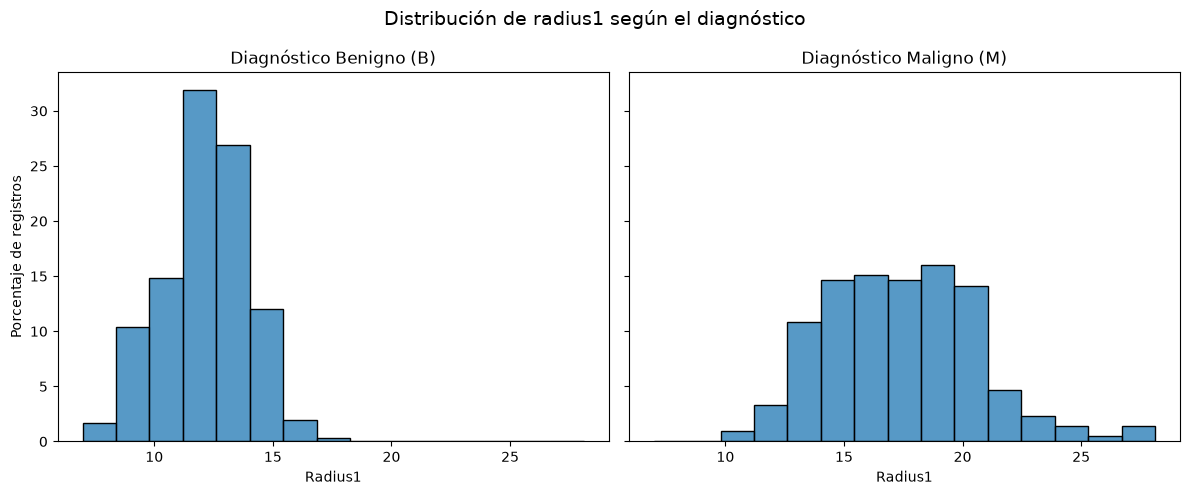

In [10]:

# ============================================================
# GRÁFICA 2: DISTRIBUCIÓN DE RADIUS1 POR DIAGNÓSTICO
# ============================================================

# Crear dos gráficas lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# Obtener el rango común para comparar ambos grupos
min_radius = df["radius1"].min()
max_radius = df["radius1"].max()

# Separar los diagnósticos
for ax, diagnosis, label in zip(
    axes,
    ["B", "M"],
    ["Benigno (B)", "Maligno (M)"]
):

    # Filtrar los registros de cada diagnóstico
    data = df[df["Diagnosis"] == diagnosis]

    # Crear histograma
    sns.histplot(
        data=data,
        x="radius1",
        bins=15,
        binrange=(min_radius, max_radius),
        stat="percent",
        ax=ax
    )

    # Personalizar gráfica
    ax.set_title(f"Diagnóstico {label}")
    ax.set_xlabel("Radius1")
    ax.set_ylabel("Porcentaje de registros")

# Título general
fig.suptitle(
    "Distribución de radius1 según el diagnóstico",
    fontsize=14
)

plt.tight_layout()

# Guardar gráfica
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURES_DIR / "figura_2_histograma_radius1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


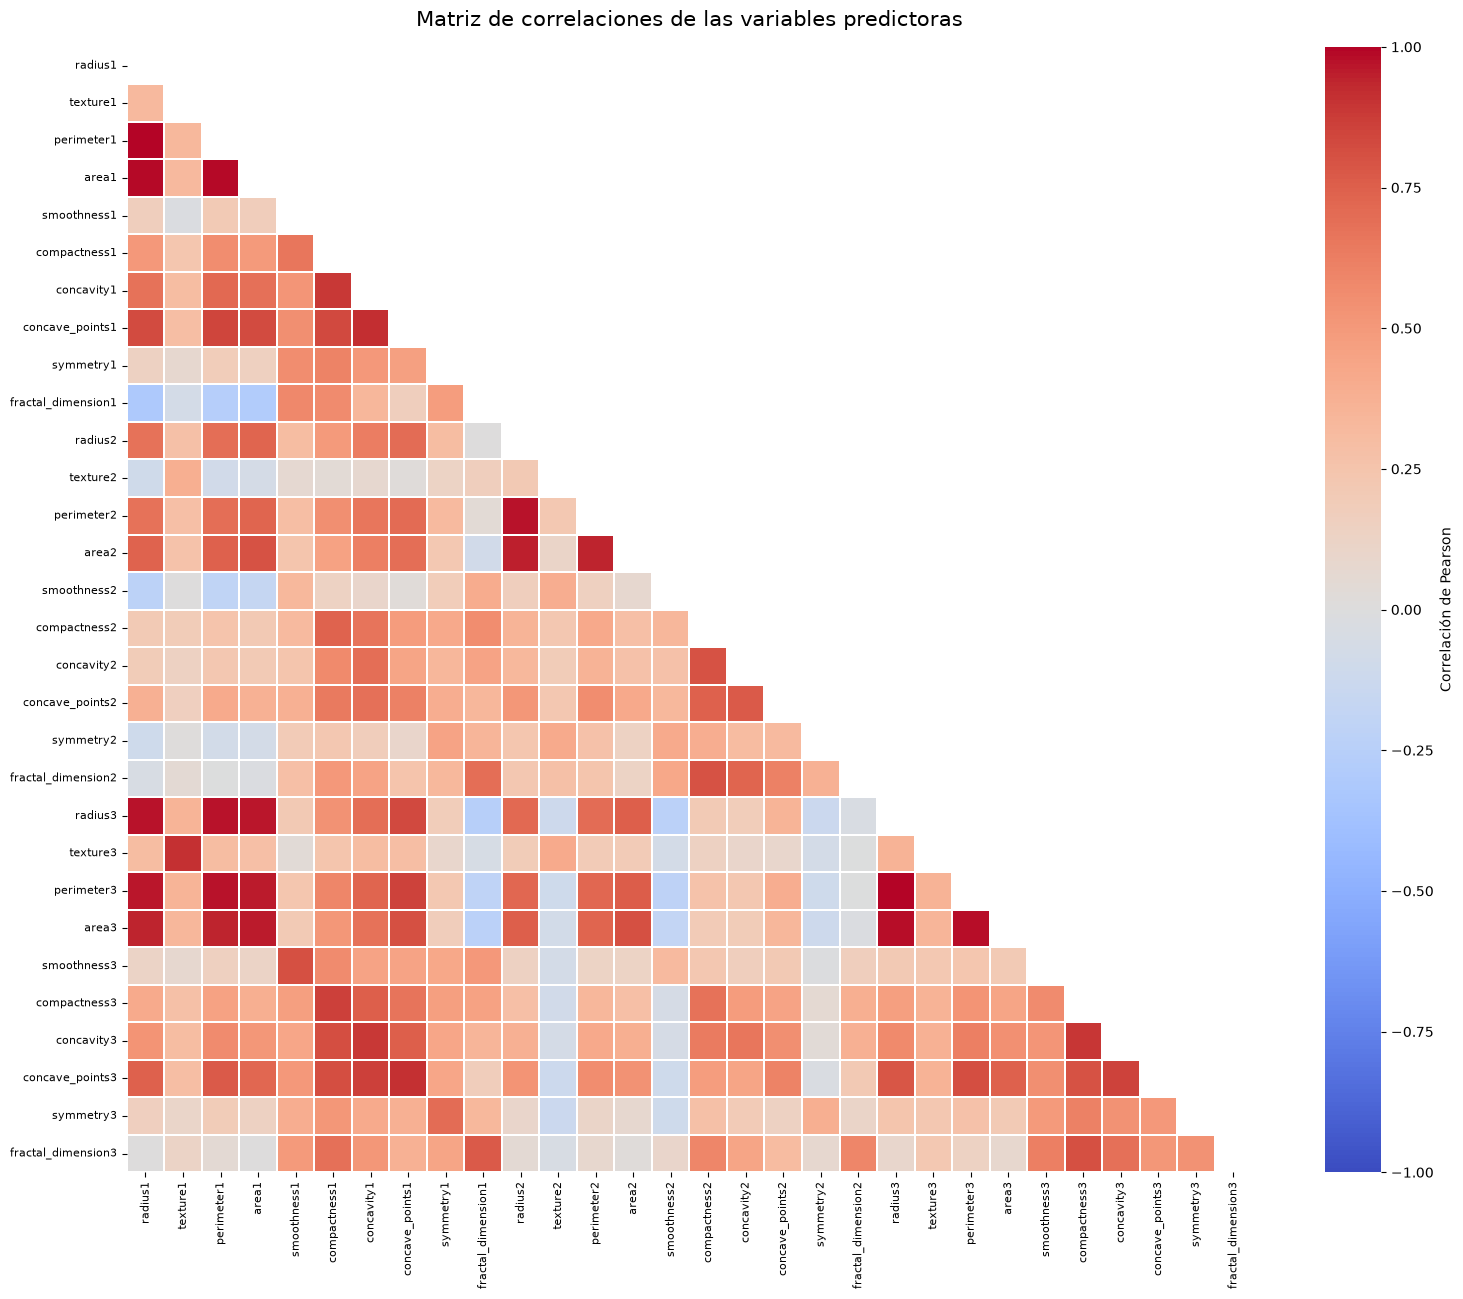

LAS 10 CORRELACIONES MÁS FUERTES


,Variable 1,Variable 2,Correlación
0,perimeter1,radius1,0.998
1,perimeter3,radius3,0.994
2,area1,radius1,0.987
3,area1,perimeter1,0.987
4,area3,radius3,0.984
5,area3,perimeter3,0.978
6,perimeter2,radius2,0.973
7,perimeter1,perimeter3,0.970
8,radius1,radius3,0.970
9,perimeter1,radius3,0.969


In [11]:

# ============================================================
# GRÁFICA 3: MATRIZ DE CORRELACIONES
# ============================================================

# Seleccionar únicamente las 30 variables predictoras
# Excluimos ID y Diagnosis
X_corr = df.drop(columns=["ID", "Diagnosis"])


# ============================================================
# 1. CALCULAR LAS CORRELACIONES
# ============================================================

# Calcular correlaciones de Pearson
correlation_matrix = X_corr.corr(method="pearson")


# ============================================================
# 2. CONSTRUIR LA MATRIZ DE CORRELACIONES
# ============================================================

# Crear una máscara para mostrar solamente la mitad inferior
mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool)
)

# Crear figura
fig, ax = plt.subplots(figsize=(16, 13))

# Crear mapa de calor
sns.heatmap(
    correlation_matrix,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.3,
    cbar_kws={"label": "Correlación de Pearson"},
    ax=ax
)

# Personalizar gráfica
ax.set_title(
    "Matriz de correlaciones de las variables predictoras",
    fontsize=15,
    pad=15
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=90,
    fontsize=8
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=8
)

plt.tight_layout()


# ============================================================
# 3. GUARDAR LA GRÁFICA
# ============================================================

from config import FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURES_DIR / "figura_3_matriz_correlaciones.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 4. OBTENER LAS 10 CORRELACIONES MÁS FUERTES
# ============================================================

# Convertir la matriz en una serie de parejas de variables
correlation_pairs = correlation_matrix.unstack()

# Eliminar las correlaciones de una variable consigo misma
correlation_pairs = correlation_pairs[
    correlation_pairs.index.get_level_values(0) !=
    correlation_pairs.index.get_level_values(1)
]

# Evitar mostrar cada pareja dos veces
correlation_pairs = correlation_pairs[
    correlation_pairs.index.get_level_values(0) <
    correlation_pairs.index.get_level_values(1)
]

# Ordenar por el valor absoluto de la correlación
# Así encontramos las relaciones positivas y negativas más fuertes
top_correlations = correlation_pairs.reindex(
    correlation_pairs.abs().sort_values(ascending=False).index
)

# Seleccionar las 10 correlaciones más fuertes
top_10 = top_correlations.head(10)

# Convertir el resultado en una tabla
top_10_df = top_10.rename("Correlación").reset_index()

top_10_df.columns = [
    "Variable 1",
    "Variable 2",
    "Correlación"
]

# Mostrar resultados
print("LAS 10 CORRELACIONES MÁS FUERTES")

display(top_10_df.round(3))
